In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from glob import glob
from dask.distributed import Client

In [2]:
client = Client(threads_per_worker=1)
client

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/node.py:188: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 33571 instead
  warnings.warn(


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/33571/status,
Dashboard: /proxy/33571/status,Workers: 28
Total threads: 28,Total memory: 125.19 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:33949,Workers: 0
Dashboard: /proxy/33571/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:45409,Total threads: 1
Dashboard: /proxy/44081/status,Memory: 4.47 GiB
Nanny: tcp://127.0.0.1:41329,


In [4]:
paths = glob('/g/data/x77/wgh581/Post_Process/CMIP6_CMIP7_Subset/mlotst*.nc')

In [26]:
ds = {}
for p in paths:
    model = p.split('_')[5]
    ds[model] = xr.open_dataset(p)['mlotst']

In [27]:
for m in list(ds.keys())[1:]:
    ds[m]['time'] = ds['MRI-ESM2-0']['time'].values

In [30]:
ds = xr.Dataset(ds).to_dataarray()

In [39]:
ds_feb = ds.groupby('time.month').mean('time').isel(month=1)

In [40]:
ds_aug = ds.groupby('time.month').mean('time').isel(month=7)

In [73]:
land_mask = np.where(np.any(np.isnan(ds), axis=0), 1, np.nan)[0,:,:]
land_mask[23:,73]=np.nan
land_mask = xr.DataArray(land_mask, dims=['lat','lon'], coords={'lat':ds['lat'], 'lon':ds['lon']})

In [78]:
import cmocean as cm
import cartopy.crs as ccrs

In [82]:
import matplotlib.path as mpath

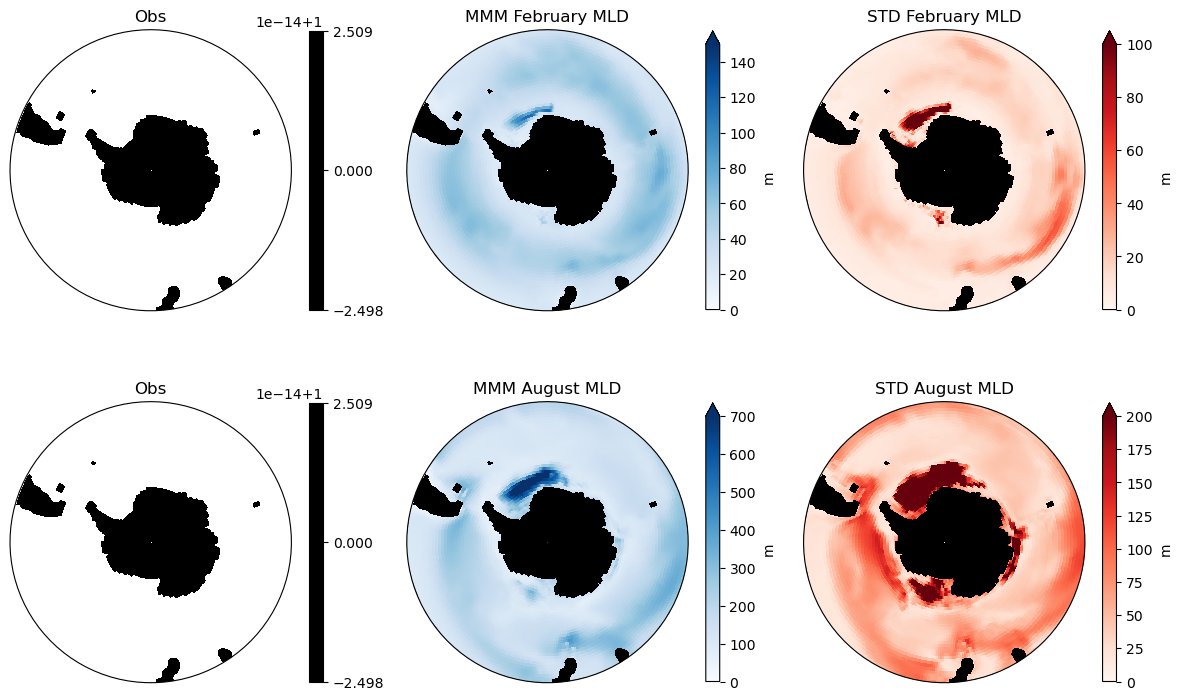

In [106]:
projection = ccrs.SouthPolarStereo()

fig, axs = plt.subplots(2, 3, figsize=(12, 8),
                        subplot_kw={"projection": projection})

for ax in axs.flatten():
    if ax not in [axs[0,0], axs[1,0]]:
        ax.set_facecolor('k')
    ax.set_extent([-280, 80, -80, -40], crs=ccrs.PlateCarree())
    
    theta = np.linspace(0, 2 * np.pi, 100)
    center, radius = [0.5, 0.5], 0.5
    verts = np.vstack([np.sin(theta), np.cos(theta)]).T
    circle = mpath.Path(verts * radius + center)
    ax.set_boundary(circle, transform=ax.transAxes)
    if ax not in [axs[0,0], axs[1,0]]:
        land_mask.plot.contourf(ax=ax, colors=['k'], add_colorbar=False, zorder=2,
                                transform=ccrs.PlateCarree())
    else:
        land_mask.plot.contourf(ax=ax, colors=['k'], cbar_kwargs={'shrink':.7}, zorder=2,
                                transform=ccrs.PlateCarree())

ds_feb.mean('variable').plot(ax=axs[0,1], vmin=0, vmax=150, cmap='Blues', zorder=1,
                             transform=ccrs.PlateCarree(), 
                             cbar_kwargs={'shrink':.7, 'label':'m'})

ds_aug.mean('variable').plot(ax=axs[1,1], vmin=0, vmax=700, cmap='Blues', zorder=1,
                             transform=ccrs.PlateCarree(), 
                             cbar_kwargs={'shrink':.7, 'label':'m'})

ds_feb.std('variable').plot(ax=axs[0,2], vmin=0, vmax=100, cmap='Reds', zorder=1,
                             transform=ccrs.PlateCarree(), 
                             cbar_kwargs={'shrink':.7, 'label':'m'})

ds_aug.std('variable').plot(ax=axs[1,2], vmin=0, vmax=200, cmap='Reds', zorder=1,
                             transform=ccrs.PlateCarree(), 
                             cbar_kwargs={'shrink':.7, 'label':'m'})
axs[0,0].set_title('Obs');
axs[1,0].set_title('Obs');
axs[0,1].set_title('MMM February MLD');
axs[1,1].set_title('MMM August MLD');
axs[0,2].set_title('STD February MLD');
axs[1,2].set_title('STD August MLD');
plt.tight_layout();
plt.savefig('/g/data/x77/jn8053/11-CMIP7/MLD_FebAug.jpg', bbox_inches='tight')

In [109]:
ds_sep = ds.groupby('time.month').mean('time').isel(month=9)

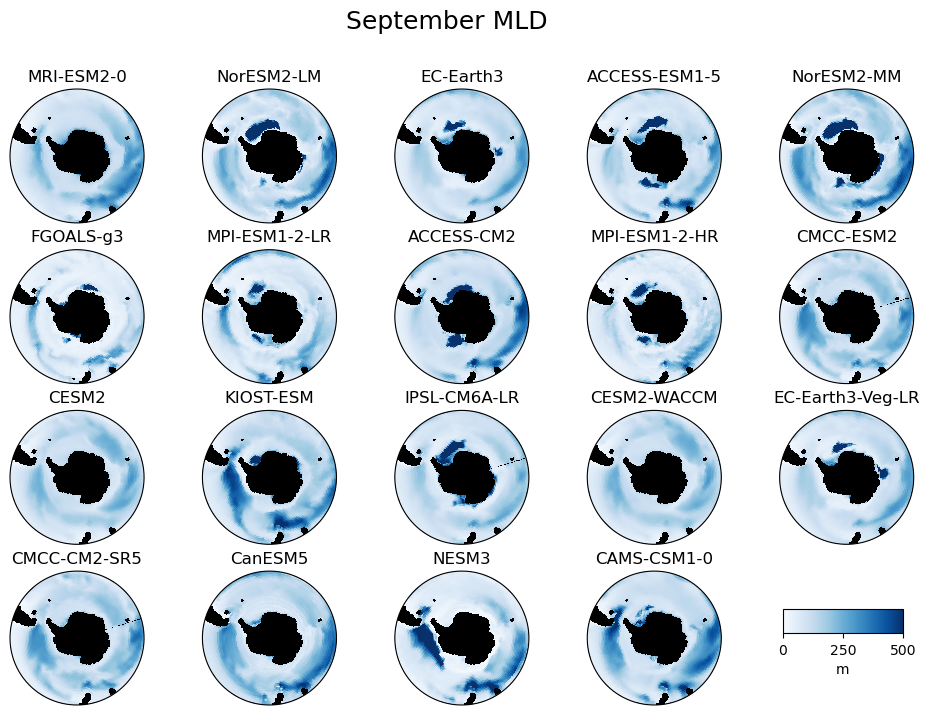

In [124]:
fig, axs = plt.subplots(4, 5, figsize=(12, 8),
                        subplot_kw={"projection": projection})
axs=axs.flatten()
for ax in axs:
    ax.set_facecolor('k')
    ax.set_extent([-280, 80, -80, -40], crs=ccrs.PlateCarree())
    
    theta = np.linspace(0, 2 * np.pi, 100)
    center, radius = [0.5, 0.5], 0.5
    verts = np.vstack([np.sin(theta), np.cos(theta)]).T
    circle = mpath.Path(verts * radius + center)
    ax.set_boundary(circle, transform=ax.transAxes)
    land_mask.plot.contourf(ax=ax, colors=['k'], add_colorbar=False, zorder=2,
                            transform=ccrs.PlateCarree())
n=0
for v in ds_sep['variable']:
    c=ds_sep.sel(variable=v).plot(ax=axs[n], vmin=0, vmax=500, cmap='Blues', zorder=1,
                             transform=ccrs.PlateCarree(), 
                             add_colorbar=False)
    axs[n].set_title(v.item());
    n+=1
plt.colorbar(c, cax=fig.add_subplot([.78, .2, .1, .03]), orientation='horizontal').set_label('m');
axs[-1].remove();
fig.suptitle('September MLD', fontsize=18);
plt.savefig('/g/data/x77/jn8053/11-CMIP7/MLD_Sep.jpg', bbox_inches='tight')

In [126]:
ds_sep_max = ds_sep.max('lat')

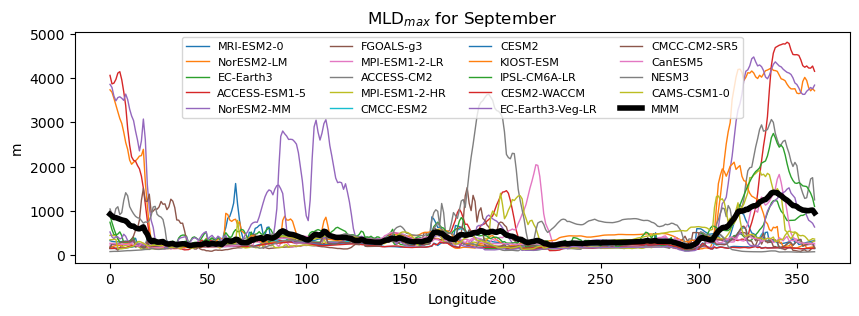

In [147]:
plt.figure(figsize=(10,3))
for v in ds['variable'].values:
    ds_sep_max.sel(variable=v).plot(linewidth=1, label=v)
ds_sep_max.mean('variable').plot(c='k', linewidth=4, label='MMM')
plt.title('MLD$_{max}$ for September');
plt.xlabel('Longitude');
plt.ylabel('m');
plt.legend(ncol=4, fontsize=8);

To do: 
1. Time series of maximum for different sectors - subduction regions vs subpolar regions
2. Month of maximum